1. Core Building Blocks of a Mesh

Every meshing algorithm produces two main lists of data that define the geometry:
• Nodes (Vertices): A list of exact (x, y) or (x, y, z) coordinates in space. Each node gets a unique ID number (0, 1, 2...).
• Elements (Connectivity): A table telling the computer which nodes connect together to form each shape. For example, a quadrilateral element might be stored as [0, 1, 8, 7].
• Degrees of Freedom (DOFs): The physical values calculated at each node, such as displacement, rotation, or temperature.



2. Main Types of Meshing Algorithms

Algorithms are grouped by how they organize elements and what shapes they create.

A. Structured Meshing (Transfinite Interpolation / Isoparametric Mapping)

• How it works: It takes a clean, regular grid (like a checkerboard) and stretches or bends it mathematically to fit inside a 4-sided shape. This is the exact method used in your Q4 Python script.
• Pros: Very fast to compute, uses little memory, and produces high-accuracy results.
• Cons: Only works easily on simple 4-sided blocks (or shapes manually split into 4-sided blocks).

B. Unstructured Meshing (Delaunay Triangulation & Advancing Front)

• How it works: For complex shapes with holes or curves, algorithms place points freely and connect them into triangles or tetrahedra. Delaunay triangulation connects points so no node sits inside the circumcircle of any triangle, avoiding skinny, distorted shapes. Advancing Front starts at the outer boundary edges and marches inward, adding elements layer by layer until the middle is filled.
• Pros: Fully automatic for any complex geometry.
• Cons: Requires more elements and memory than structured meshes.

C. Quad-Dominant & Paving Algorithms

• How it works: Algorithms like Paving march inward from boundaries specifically to build 4-sided quadrilateral elements instead of triangles.
• Pros: Quads generally give better accuracy for bending and structural stress than triangles.

3. Essential Rules for a "Good" Mesh

A meshing algorithm must follow strict geometric rules so the math solver does not crash:
• Node Ordering (Winding): Element nodes must always be listed in counter-clockwise (CCW) order. Listing them clockwise flips the element "inside out," causing a negative Jacobian determinant error.
• No Hanging Nodes: A corner of one element should never touch the middle of a neighboring element's edge. Every edge must be shared completely by two adjacent elements.
• Good Aspect Ratio: Elements should look close to a regular square or equilateral triangle. Long, skinny elements or sharp angles cause large mathematical errors.
• Mesh Density (Refinement): Use smaller elements where stress changes rapidly (like sharp corners or holes) and larger elements in flat, calm areas to save computer time.

4. Standard Workflow of a Meshing Program

1. Define Geometry: Input corner points, boundary curves, or a CAD model.
2. Seed Boundaries: Decide how many divisions (nx, ny) or what element size to place along the outer edges.
3. Generate Interior Nodes: Calculate the (x, y) coordinates for all points inside the boundary.
4. Build Connectivity: Group nearby nodes into valid, non-overlapping elements in CCW order.
5. Check Quality: Verify that all elements have positive areas and acceptable angles before solving.

Generates a structured Q4 (4-node quadrilateral) finite element mesh for any arbitrary convex quadrilateral using bilinear isoparametric mapping, along with the basic Reissner-Mindlin plate formulation (3 DOFs per node: transverse deflection \(w\), and rotations \(\theta_x, \theta_y\)).

[array([0., 0.]), array([0.66666667, 0.08333333]), array([1.33333333, 0.16666667]), array([2.  , 0.25]), array([2.66666667, 0.33333333]), array([3.33333333, 0.41666667]), array([4. , 0.5]), array([0.1, 0.5]), array([0.73333333, 0.58333333]), array([1.36666667, 0.66666667]), array([2.  , 0.75]), array([2.63333333, 0.83333333]), array([3.26666667, 0.91666667]), array([3.9, 1. ]), array([0.2, 1. ]), array([0.8       , 1.08333333]), array([1.4       , 1.16666667]), array([2.  , 1.25]), array([2.6       , 1.33333333]), array([3.2       , 1.41666667]), array([3.8, 1.5]), array([0.3, 1.5]), array([0.86666667, 1.58333333]), array([1.43333333, 1.66666667]), array([2.  , 1.75]), array([2.56666667, 1.83333333]), array([3.13333333, 1.91666667]), array([3.7, 2. ]), array([0.4, 2. ]), array([0.93333333, 2.08333333]), array([1.46666667, 2.16666667]), array([2.  , 2.25]), array([2.53333333, 2.33333333]), array([3.06666667, 2.41666667]), array([3.6, 2.5]), array([0.5, 2.5]), array([1.        , 2.583333

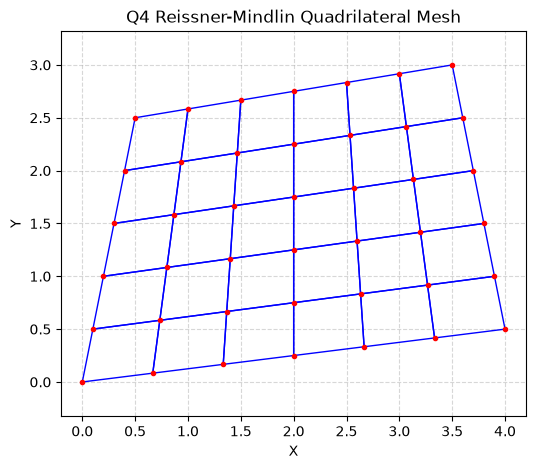

In [ ]:
import matplotlib.pyplot as plt  # Library for plotting and visualizing the mesh
import numpy as np  # Library for fast matrix and array math


def generate_q4_mesh(corners, nx, ny):

    """Generates a structured Q4 mesh for an arbitrary quadrilateral.

    Parameters:
    corners : array-like of shape (4, 2)
        The (x, y) coordinates of the 4 corners in counter-clockwise order:
        [Bottom-Left, Bottom-Right, Top-Right, Top-Left]
    nx : int
        Number of elements along the xi-direction (bottom/top edges)
    ny : int
        Number of elements along the eta-direction (left/right edges)

    Returns:
    nodes : ndarray of shape ((nx+1)*(ny+1), 2)   Nodal (x, y) coordinates
    elements : ndarray of shape (nx*ny, 4)
        Element connectivity (0-based node indices in CCW order)
    dof_map : ndarray of shape ((nx+1)*(ny+1), 3)
        Reissner-Mindlin DOFs [w, theta_x, theta_y] per node
    """



    """Generates a structured 4-node quadrilateral (Q4) mesh for any convex quadrilateral."""
    # Convert the input list of 4 corner coordinates into a 4x2 floating-point NumPy array.
    # Row 0: Bottom-Left, Row 1: Bottom-Right, Row 2: Top-Right, Row 3: Top-Left.
    corners = np.asarray(corners, dtype=float)

    # Create evenly spaced points in the "natural" (parent) coordinate system [-1, 1].
    # If there are 'nx' elements along an edge, we need 'nx + 1' nodes.
    xi = np.linspace(-1.0, 1.0, nx + 1)  # Horizontal parent axis (-1 to +1)
    eta = np.linspace(-1.0, 1.0, ny + 1)  # Vertical parent axis (-1 to +1)

    # List to store the physical (x, y) coordinates of every generated node
    nodes = []

    # Loop row-by-row (bottom to top) and column-by-column (left to right)
    for e in eta:
        for x in xi:
            # Evaluate the 4 standard bilinear Lagrange shape functions at (x, e).
            # Each shape function equals 1 at its own corner and 0 at the other three.
            N1 = 0.25 * (1.0 - x) * (1.0 - e)  # Weight for Bottom-Left corner (-1, -1)
            N2 = 0.25 * (1.0 + x) * (1.0 - e)  # Weight for Bottom-Right corner (+1, -1)
            N3 = 0.25 * (1.0 + x) * (1.0 + e)  # Weight for Top-Right corner (+1, +1)
            N4 = 0.25 * (1.0 - x) * (1.0 + e)  # Weight for Top-Left corner (-1, +1)

            # Group the 4 weights into a 1D vector of length 4
            N = np.array([N1, N2, N3, N4])

            # Isoparametric mapping: multiply shape function weights [1x4] by corner coords [4x2]
            # Formula: x = sum(Ni * xi), y = sum(Ni * yi)
            pt = N @ corners # calculate the physical (x, y) coordinates of the node in the real quadrilateral  
            nodes.append(pt)

    print(nodes)

    # Convert the list of node coordinates into a 2D NumPy array of shape (total_nodes, 2)
    nodes = np.array(nodes)

    # List to store the 4 node indices that make up each quadrilateral element
    elements = []

    # Loop over every element cell in the grid (ny rows by nx columns)
    for j in range(ny):  # Element row index
        for i in range(nx):  # Element column index
            # Calculate global node indices for the 4 corners of the current element.
            # Each row has (nx + 1) nodes, so moving up one row adds (nx + 1) to the index.
            n1 = j * (nx + 1) + i  # Bottom-Left node of element
            n2 = n1 + 1  # Bottom-Right node of element
            n3 = n2 + (nx + 1)  # Top-Right node of element
            n4 = n1 + (nx + 1)  # Top-Left node of element

            # Store nodes in Counter-Clockwise (CCW) order.
            # CCW order is mandatory in FEM so the Jacobian determinant stays positive.
            elements.append([n1, n2, n3, n4])

    # Convert connectivity list into an integer array of shape (total_elements, 4)
    elements = np.array(elements, dtype=int)

    # Reissner-Mindlin Plate Theory assigns 3 Degrees of Freedom (DOFs) per node:
    # DOF 0: Transverse deflection (w)
    # DOF 1: Bending rotation about x-axis (theta_x)
    # DOF 2: Bending rotation about y-axis (theta_y)
    num_nodes = len(nodes)

    # Assign consecutive global equation numbers [0, 1, 2, ...] reshaped into (num_nodes, 3)
    # Example: Node 0 gets DOFs, Node 1 gets, etc.
    dof_map = np.arange(num_nodes * 3).reshape(num_nodes, 3)

    return nodes, elements, dof_map


def plot_mesh(nodes, elements):
    """Visualizes the generated nodes and quadrilateral elements."""
    plt.figure(figsize=(6, 5))  # Create a figure window of size 6x5 inches

    # Loop through each element's 4 node indices
    for el in elements:
        # Retrieve the (x, y) coordinates of the 4 nodes, and append the 1st node at the end
        # so the plotted line closes the 4-sided polygon loop (n1 -> n2 -> n3 -> n4 -> n1).
        poly = np.vstack([nodes[el], nodes[el[0]]])
        plt.plot(poly[:, 0], poly[:, 1], 'b-', lw=1)  # Draw element edges in blue

    # Plot all nodal points as red dots on top of the grid lines
    plt.plot(nodes[:, 0], nodes[:, 1], 'ro', markersize=3)

    plt.title('Q4 Reissner-Mindlin Quadrilateral Mesh')  # Add chart title
    plt.xlabel('X')  # Label X-axis
    plt.ylabel('Y')  # Label Y-axis
    plt.axis('equal')  # Ensure 1 unit on X equals 1 unit on Y (prevents visual distortion)
    plt.grid(True, linestyle='--', alpha=0.5)  # Add a light background reference grid
    plt.show()  # Display the plot window


# ==========================================
# Example Usage
# ==========================================
if __name__ == '__main__':
    # Define the 4 physical corners of an arbitrary skewed quadrilateral.
    # IMPORTANT: Must be listed in Counter-Clockwise (CCW) order.
    quad_corners = [
        [0.0, 0.0],  # Corner 1: Bottom-Left
        [4.0, 0.5],  # Corner 2: Bottom-Right
        [3.5, 3.0],  # Corner 3: Top-Right
        [0.5, 2.5],  # Corner 4: Top-Left
    ]

    nx, ny = 6, 5  # Divide into 6 elements horizontally and 5 elements vertically (30 total)

    # Call the mesher function
    nodes, elements, dof_map = generate_q4_mesh(quad_corners, nx, ny)

    # Print summary statistics of the finite element model
    print(f'Total Nodes: {len(nodes)}')  # (6+1) * (5+1) = 42 nodes
    print(f'Total Q4 Elements: {len(elements)}')  # 6 * 5 = 30 elements
    print(f'Total Reissner-Mindlin DOFs: {dof_map.size}')  # 42 nodes * 3 DOFs = 126 DOFs

    # Print the node index connectivity for the first 3 elements
    print('\nFirst 3 Elements (Node Indices):')
    print(elements[:3])

    # Render the visual plot of the mesh
    plot_mesh(nodes, elements)


Any Shape

--- MESH QUALITY REPORT ---
num_nodes: 101
num_elements: 163
min_area: 0.0492
worst_min_angle_deg: 30.8015
avg_min_angle_deg: 54.8775


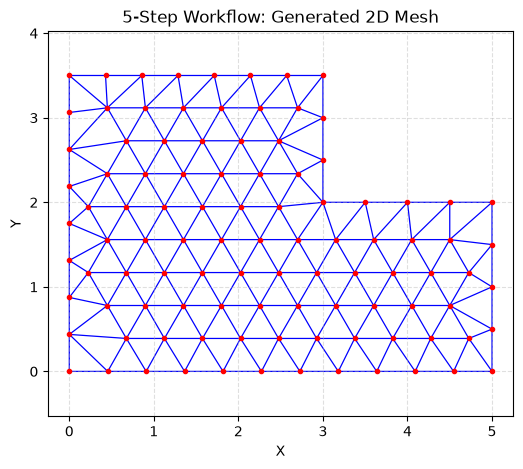

In [3]:
import matplotlib.path as mpath
import matplotlib.pyplot as plt
import numpy as np
from scipy.spatial import Delaunay


# =========================================================
# STEP 1: Define Geometry
# =========================================================
def step1_define_geometry():
    """Defines the physical domain using counter-clockwise boundary vertices."""
    # Example: A notched bracket (non-convex polygon)
    polygon_vertices = np.array(
        [
            [0.0, 0.0],
            [5.0, 0.0],
            [5.0, 2.0],
            [3.0, 2.0],
            [3.0, 3.5],
            [0.0, 3.5],
        ],
        dtype=float,
    )

    target_element_size = 0.45
    return polygon_vertices, target_element_size


# =========================================================
# STEP 2: Seed Boundaries
# =========================================================
def step2_seed_boundaries(vertices, h):
    """Places evenly spaced nodes along every outer boundary edge."""
    boundary_nodes = []
    num_edges = len(vertices)

    for i in range(num_edges):
        p_start = vertices[i]
        p_end = vertices[(i + 1) % num_edges]

        # Calculate edge length and number of segments
        edge_length = np.linalg.norm(p_end - p_start)
        num_divisions = max(1, int(np.round(edge_length / h)))

        # Interpolate points along the edge (skip endpoint to prevent duplicates)
        for k in range(num_divisions):
            fraction = k / num_divisions
            pt = (1.0 - fraction) * p_start + fraction * p_end
            boundary_nodes.append(pt)

    return np.array(boundary_nodes)


# =========================================================
# STEP 3: Generate Interior Nodes
# =========================================================
def step3_generate_interior_nodes(vertices, boundary_nodes, h):
    """Fills the interior of the shape with staggered grid points."""
    poly_path = mpath.Path(vertices)
    xmin, ymin = vertices.min(axis=0)
    xmax, ymax = vertices.max(axis=0)

    # Vertical spacing for equilateral triangles
    dy = h * np.sqrt(3) / 2.0
    interior_nodes = []

    row = 0
    y = ymin + dy
    while y < ymax:
        # Offset alternating rows by half an element width
        x_shift = (h / 2.0) if (row % 2 == 1) else 0.0
        x = xmin + (h / 2.0) + x_shift

        while x < xmax:
            candidate_pt = np.array([x, y])

            # Keep point only if inside polygon and safely away from boundary nodes
            if poly_path.contains_point(candidate_pt):
                dist_to_boundary = np.min(
                    np.linalg.norm(boundary_nodes - candidate_pt, axis=1)
                )
                if dist_to_boundary > 0.55 * h:
                    interior_nodes.append(candidate_pt)
            x += h

        y += dy
        row += 1

    # Combine boundary and interior nodes into one master node table
    if len(interior_nodes) > 0:
        all_nodes = np.vstack([boundary_nodes, np.array(interior_nodes)])
    else:
        all_nodes = boundary_nodes

    return all_nodes


# =========================================================
# STEP 4: Build Connectivity
# =========================================================
def step4_build_connectivity(vertices, nodes):
    """Connects nodes into valid, counter-clockwise triangle elements."""
    poly_path = mpath.Path(vertices)

    # Run Delaunay triangulation on all nodes
    tri = Delaunay(nodes)
    valid_elements = []

    for simplex in tri.simplices:
        pts = nodes[simplex]
        centroid = pts.mean(axis=0)

        # Discard triangles that fall outside concave notches
        if poly_path.contains_point(centroid):
            # Enforce Counter-Clockwise (CCW) node ordering
            signed_area2 = (pts[1, 0] - pts[0, 0]) * (
                pts[2, 1] - pts[0, 1]
            ) - (pts[2, 0] - pts[0, 0]) * (pts[1, 1] - pts[0, 1])

            if signed_area2 > 1e-12:
                valid_elements.append(simplex)
            elif signed_area2 < -1e-12:
                # Swap two nodes to reverse clockwise winding into CCW
                valid_elements.append([simplex[0], simplex[2], simplex[1]])

    return np.array(valid_elements, dtype=int)


# =========================================================
# STEP 5: Check Quality
# =========================================================
def step5_check_quality(nodes, elements):
    """Verifies positive element areas and computes minimum interior angles."""
    min_angles = []
    areas = []

    for el in elements:
        p0, p1, p2 = nodes[el]

        # Compute side lengths
        a = np.linalg.norm(p2 - p1)
        b = np.linalg.norm(p2 - p0)
        c = np.linalg.norm(p1 - p0)

        # Compute element area
        area = 0.5 * abs(
            (p1[0] - p0[0]) * (p2[1] - p0[1])
            - (p2[0] - p0[0]) * (p1[1] - p0[1])
        )
        areas.append(area)

        # Law of Cosines to find all 3 interior angles (in degrees)
        cos_A = np.clip((b**2 + c**2 - a**2) / (2 * b * c), -1.0, 1.0)
        cos_B = np.clip((a**2 + c**2 - b**2) / (2 * a * c), -1.0, 1.0)
        cos_C = np.clip((a**2 + b**2 - c**2) / (2 * a * b), -1.0, 1.0)

        angles = np.degrees(np.arccos([cos_A, cos_B, cos_C]))
        min_angles.append(np.min(angles))

    report = {
        'num_nodes': len(nodes),
        'num_elements': len(elements),
        'min_area': float(np.min(areas)),
        'worst_min_angle_deg': float(np.min(min_angles)),
        'avg_min_angle_deg': float(np.mean(min_angles)),
    }
    return report


# =========================================================
# Main Execution Pipeline
# =========================================================
if __name__ == '__main__':
    # Execute the 5-step workflow sequentially
    geom_vertices, h_size = step1_define_geometry()
    b_nodes = step2_seed_boundaries(geom_vertices, h_size)
    nodes = step3_generate_interior_nodes(geom_vertices, b_nodes, h_size)
    elements = step4_build_connectivity(geom_vertices, nodes)
    quality = step5_check_quality(nodes, elements)

    # Display Quality Report
    print('--- MESH QUALITY REPORT ---')
    for key, val in quality.items():
        print(
            f'{key}: {val:.4f}' if isinstance(val, float) else f'{key}: {val}'
        )

    # Visualize Final Mesh
    plt.figure(figsize=(6, 5))
    plt.triplot(nodes[:, 0], nodes[:, 1], elements, 'b-', lw=0.9)
    plt.plot(nodes[:, 0], nodes[:, 1], 'ro', markersize=3)
    plt.title('5-Step Workflow: Generated 2D Mesh')
    plt.xlabel('X')
    plt.ylabel('Y')
    plt.axis('equal')
    plt.grid(True, linestyle='--', alpha=0.4)
    plt.show()


Above  

• Data Separation: Separating step2 and step3 keeps boundary nodes fixed on the exact CAD edges while letting interior nodes fill space freely.

• Winding Verification: step4 checks the sign of the cross product (signed_area2) to guarantee every triangle is ordered counter-clockwise before saving.

• Quality Gate: step5 flags degenerate elements (min_area <= 0) and tracks the smallest interior angle (angles above 30° generally indicate a healthy triangular mesh).


--- QUALITY BEFORE SMOOTHING ---
Worst Min Angle: 30.80 deg
Avg Min Angle:   54.88 deg

--- QUALITY AFTER SMOOTHING ---
Worst Min Angle: 38.50 deg
Avg Min Angle:   54.52 deg


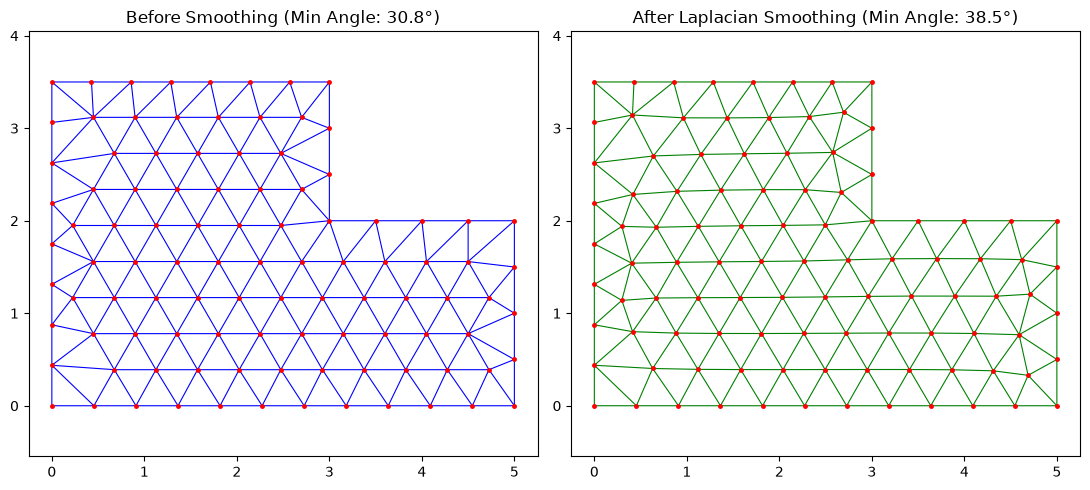

In [11]:
import matplotlib.path as mpath  # Tool to check if a point lies inside or outside a polygon
import matplotlib.pyplot as plt  # Library for plotting and comparing meshes
import numpy as np  # Library for fast array and vector math
from scipy.spatial import Delaunay  # Built-in Delaunay triangulation algorithm


# =========================================================
# STEP 1: Define Geometry
# =========================================================
def step1_define_geometry():
    """Defines the physical shape (boundary) and target element size."""
    # List the outer corners of a notched bracket in Counter-Clockwise (CCW) order.
    # Each row is an [x, y] coordinate pair.
    polygon_vertices = np.array(
        [
            [0.0, 0.0],  # Bottom-left corner
            [5.0, 0.0],  # Bottom-right corner
            [5.0, 2.0],  # Middle-right corner
            [3.0, 2.0],  # Inner notch corner (concave)
            [3.0, 3.5],  # Top-right corner
            [0.0, 3.5],  # Top-left corner
        ],
        dtype=float,
    )

    # Desired average length of each triangle edge (smaller = finer mesh, more elements)
    target_element_size = 0.45
    return polygon_vertices, target_element_size


# =========================================================
# STEP 2: Seed Boundaries
# =========================================================
def step2_seed_boundaries(vertices, h):
    """Places evenly spaced nodes along every outer edge of the polygon."""
    boundary_nodes = []  # List to collect all outer boundary coordinates
    num_edges = len(vertices)  # A 6-sided polygon has 6 outer edges

    # Loop through each edge connecting vertex `i` to vertex `i + 1`
    for i in range(num_edges):
        p_start = vertices[i]  # Starting corner of the current edge
        # `% num_edges` wraps the last vertex back around to vertex 0 to close the loop
        p_end = vertices[(i + 1) % num_edges]

        # Calculate the straight-line Euclidean distance between start and end corners
        edge_length = np.linalg.norm(p_end - p_start)

        # Calculate how many segments fit along this edge (at least 1 segment)
        num_divisions = max(1, int(np.round(edge_length / h)))

        # Generate intermediate points along the edge using linear interpolation.
        # Stop at `num_divisions - 1` so we don't duplicate the corner point on the next edge.
        for k in range(num_divisions):
            fraction = k / num_divisions  # Goes from 0.0 up to (N-1)/N
            pt = (1.0 - fraction) * p_start + fraction * p_end
            boundary_nodes.append(pt)

    return np.array(boundary_nodes)


# =========================================================
# STEP 3: Generate Interior Nodes
# =========================================================
def step3_generate_interior_nodes(vertices, boundary_nodes, h):
    """Fills the inside of the polygon with a staggered grid of points."""
    # Create a mathematical boundary object for fast "point-in-polygon" checks
    poly_path = mpath.Path(vertices)

    # Find the rectangular bounding box surrounding the entire polygon
    xmin, ymin = vertices.min(axis=0)
    xmax, ymax = vertices.max(axis=0)

    # Ideal vertical row spacing for equilateral triangles: h * sin(60°) = h * sqrt(3)/2
    dy = h * np.sqrt(3) / 2.0

    interior_nodes = []
    row = 0  # Track row number so we can shift odd rows
    y = ymin + dy  # Start one row above the bottom boundary

    # Sweep upward row by row until reaching the top boundary
    while y < ymax:
        # Shift every odd row horizontally by h/2 so points form triangles instead of squares
        x_shift = (h / 2.0) if (row % 2 == 1) else 0.0
        x = xmin + (h / 2.0) + x_shift

        # Sweep left to right across the current horizontal row
        while x < xmax:
            candidate_pt = np.array([x, y])

            # Check 1: Is this point strictly inside the polygon boundary?
            if poly_path.contains_point(candidate_pt):
                # Check 2: Calculate distance from this point to every boundary node
                dist_to_boundary = np.min(
                    np.linalg.norm(boundary_nodes - candidate_pt, axis=1)
                )
                # Keep the point only if it is not too close to the outer wall (prevents skinny slivers)
                if dist_to_boundary > 0.55 * h:
                    interior_nodes.append(candidate_pt)
            x += h  # Step right by one element width

        y += dy  # Step up to the next row
        row += 1

    # Stack boundary nodes on top of interior nodes into one master coordinate table.
    # Keeping boundary nodes first makes it easy to lock them during smoothing later.
    if len(interior_nodes) > 0:
        all_nodes = np.vstack([boundary_nodes, np.array(interior_nodes)])
    else:
        all_nodes = boundary_nodes

    return all_nodes


# =========================================================
# STEP 4: Build Connectivity
# =========================================================
def step4_build_connectivity(vertices, nodes):
    """Connects the cloud of nodes into valid, counter-clockwise triangles."""
    poly_path = mpath.Path(vertices)

    # Run Delaunay triangulation (creates triangles across the entire convex hull)
    tri = Delaunay(nodes)
    valid_elements = []

    # Loop through every triangle (each `simplex` is a list of 3 node indices: [n0, n1, n2])
    for simplex in tri.simplices:
        pts = nodes[simplex]  # Get the 3 (x, y) corner coordinates of this triangle
        centroid = pts.mean(axis=0)  # Calculate the geometric center of the triangle

        # Delaunay bridges across concave notches; discard any triangle whose center is outside
        if poly_path.contains_point(centroid):
            # Compute twice the signed area using the 2D cross product:
            # (x1 - x0)*(y2 - y0) - (y1 - y0)*(x2 - x0)
            signed_area2 = (pts[1, 0] - pts[0, 0]) * (
                pts[2, 1] - pts[0, 1]
            ) - (pts[1, 1] - pts[0, 1]) * (pts[2, 0] - pts[0, 0])

            # Positive area means nodes are already in Counter-Clockwise (CCW) order
            if signed_area2 > 1e-12:
                valid_elements.append(simplex)
            # Negative area means Clockwise order; swap two nodes to flip it to CCW
            elif signed_area2 < -1e-12:
                valid_elements.append([simplex[0], simplex[2], simplex[1]])

    return np.array(valid_elements, dtype=int)

def step4_5_laplacian_smoothing(
    nodes, elements, num_boundary_nodes, iterations=15, omega=0.5
):
    smoothed_nodes = np.asarray(nodes, dtype=float).copy()
    neighbors = [set() for _ in range(len(smoothed_nodes))]

    for element in elements:
        for node in element:
            neighbors[node].update(other for other in element if other != node)

    for _ in range(iterations):
        updated_nodes = smoothed_nodes.copy()
        for index in range(num_boundary_nodes, len(smoothed_nodes)):
            if neighbors[index]:
                neighbor_mean = np.mean(
                    smoothed_nodes[list(neighbors[index])], axis=0
                )
                updated_nodes[index] = (
                    (1 - omega) * smoothed_nodes[index] + omega * neighbor_mean
                )
        smoothed_nodes = updated_nodes

    return smoothed_nodes



# =========================================================
# STEP 5: Check Quality
# =========================================================
def step5_check_quality(nodes, elements):
    """Calculates element areas and interior angles to verify mesh health."""
    min_angles = []
    areas = []

    for el in elements:
        p0, p1, p2 = nodes[el]  # Corner coordinates of the triangle

        # Compute lengths of the 3 sides opposite to corners p0, p1, p2
        a = np.linalg.norm(p2 - p1)
        b = np.linalg.norm(p2 - p0)
        c = np.linalg.norm(p1 - p0)

        # Compute positive triangle area using cross product
        area = 0.5 * abs(
            (p1[0] - p0[0]) * (p2[1] - p0[1])
            - (p2[0] - p0[0]) * (p1[1] - p0[1])
        )
        areas.append(area)

        # Use the Law of Cosines to find the cosine of each interior angle.
        # `np.clip` prevents floating-point rounding errors outside [-1, 1] before `arccos`.
        cos_A = np.clip((b**2 + c**2 - a**2) / (2 * b * c), -1.0, 1.0)
        cos_B = np.clip((a**2 + c**2 - b**2) / (2 * a * c), -1.0, 1.0)
        cos_C = np.clip((a**2 + b**2 - c**2) / (2 * a * b), -1.0, 1.0)

        # Convert radians to degrees and record the smallest angle in this triangle
        angles = np.degrees(np.arccos([cos_A, cos_B, cos_C]))
        min_angles.append(np.min(angles))

    return {
        'min_area': float(np.min(areas)),  # Must be > 0 (no inverted/collapsed triangles)
        'worst_min_angle_deg': float(np.min(min_angles)),  # Higher is better (ideal is 60 deg)
        'avg_min_angle_deg': float(np.mean(min_angles)),  # Average minimum angle across mesh
    }


# =========================================================
# Main Execution & Before/After Comparison
# =========================================================
if __name__ == '__main__':
    # Run Steps 1 to 4 to create the initial raw mesh
    geom_vertices, h_size = step1_define_geometry()
    b_nodes = step2_seed_boundaries(geom_vertices, h_size)
    raw_nodes = step3_generate_interior_nodes(geom_vertices, b_nodes, h_size)
    elements = step4_build_connectivity(geom_vertices, raw_nodes)

    # Measure mesh quality BEFORE smoothing
    q_before = step5_check_quality(raw_nodes, elements)

    # Run Step 4.5: Smooth interior nodes for 15 passes while keeping len(b_nodes) fixed
    smooth_nodes = step4_5_laplacian_smoothing(
        raw_nodes, elements, num_boundary_nodes=len(b_nodes), iterations=15, omega=0.5
    )

    # Measure mesh quality AFTER smoothing
    q_after = step5_check_quality(smooth_nodes, elements)

    # Print numerical comparison
    print('--- QUALITY BEFORE SMOOTHING ---')
    print(f"Worst Min Angle: {q_before['worst_min_angle_deg']:.2f} deg")
    print(f"Avg Min Angle:   {q_before['avg_min_angle_deg']:.2f} deg\n")

    print('--- QUALITY AFTER SMOOTHING ---')
    print(f"Worst Min Angle: {q_after['worst_min_angle_deg']:.2f} deg")
    print(f"Avg Min Angle:   {q_after['avg_min_angle_deg']:.2f} deg")

    # Create a 1-row, 2-column side-by-side plot to visually compare both meshes
    fig, axes = plt.subplots(1, 2, figsize=(11, 5))

    # Left subplot: Original raw mesh
    axes[0].triplot(raw_nodes[:, 0], raw_nodes[:, 1], elements, 'b-', lw=0.8)
    axes[0].plot(raw_nodes[:, 0], raw_nodes[:, 1], 'ro', markersize=2.5)
    axes[0].set_title(
        f"Before Smoothing (Min Angle: {q_before['worst_min_angle_deg']:.1f}°)"
    )
    axes[0].axis('equal')

    # Right subplot: Smoothed mesh
    axes[1].triplot(
        smooth_nodes[:, 0], smooth_nodes[:, 1], elements, 'g-', lw=0.8
    )
    axes[1].plot(smooth_nodes[:, 0], smooth_nodes[:, 1], 'ro', markersize=2.5)
    axes[1].set_title(
        f"After Laplacian Smoothing (Min Angle: {q_after['worst_min_angle_deg']:.1f}°)"
    )
    axes[1].axis('equal')

    plt.tight_layout()  # Prevent overlapping titles/labels
    plt.show()  # Open plot window

• Mathematical Formula: For each interior node \(i\), its updated position \(\mathbf{x}_{i}^{\text{new}}\) is computed from its \(k\) connected neighbors \(j \in N(i)\):
\(\mathbf{x}_{i}^{\text{new}}=(1-\omega )\mathbf{x}_{i}^{\text{old}}+\omega \left(\frac{1}{k}\sum _{j\in N(i)}\mathbf{x}_{j}^{\text{old}}\right)\)

• Boundary Locking: Because step2 placed all boundary nodes at the start of the nodes array (0 to num_boundary_nodes - 1), the loop starts at num_boundary_nodes so outer edges stay exact.

• Damping (\(\omega = 0.5\)): Using a relaxation factor around 0.5 prevents nodes from oscillating or pulling elements inside-out near sharp concave corners.

TK
TRIA MESHING  WITH SMOOTHING OPTION 

In [10]:
import tkinter as tk
from tkinter import ttk
import matplotlib.path as mpath
from matplotlib.backends.backend_tkagg import FigureCanvasTkAgg
from matplotlib.figure import Figure
import numpy as np
from scipy.spatial import Delaunay


# =========================================================
# CORE MESHING ENGINE (Steps 1 to 5)
# =========================================================
def run_meshing_pipeline(h_size, use_smoothing, iterations):
    # Step 1: Define Geometry (Notched Bracket in CCW order)
    vertices = np.array(
        [
            [0.0, 0.0],
            [5.0, 0.0],
            [5.0, 2.0],
            [3.0, 2.0],
            [3.0, 3.5],
            [0.0, 3.5],
        ],
        dtype=float,
    )

    # Step 2: Seed Boundaries
    boundary_nodes = []
    num_edges = len(vertices)
    for i in range(num_edges):
        p_start = vertices[i]
        p_end = vertices[(i + 1) % num_edges]
        edge_len = np.linalg.norm(p_end - p_start)
        n_div = max(1, int(np.round(edge_len / h_size)))
        for k in range(n_div):
            t = k / n_div
            boundary_nodes.append((1.0 - t) * p_start + t * p_end)
    boundary_nodes = np.array(boundary_nodes)

    # Step 3: Generate Interior Nodes
    poly_path = mpath.Path(vertices)
    xmin, ymin = vertices.min(axis=0)
    xmax, ymax = vertices.max(axis=0)
    dy = h_size * np.sqrt(3) / 2.0

    interior_nodes = []
    row = 0
    y = ymin + dy
    while y < ymax:
        x_shift = (h_size / 2.0) if (row % 2 == 1) else 0.0
        x = xmin + (h_size / 2.0) + x_shift
        while x < xmax:
            pt = np.array([x, y])
            if poly_path.contains_point(pt):
                dist = np.min(np.linalg.norm(boundary_nodes - pt, axis=1))
                if dist > 0.55 * h_size:
                    interior_nodes.append(pt)
            x += h_size
        y += dy
        row += 1

    if len(interior_nodes) > 0:
        nodes = np.vstack([boundary_nodes, np.array(interior_nodes)])
    else:
        nodes = boundary_nodes

    # Step 4: Build Connectivity (Delaunay + Clipping + CCW Check)
    tri = Delaunay(nodes)
    valid_elements = []
    for simplex in tri.simplices:
        pts = nodes[simplex]
        if poly_path.contains_point(pts.mean(axis=0)):
            area2 = (pts[1, 0] - pts[0, 0]) * (pts[2, 1] - pts[0, 1]) - (
                pts[1, 1] - pts[0, 1]
            ) * (pts[2, 0] - pts[0, 0])
            if area2 > 1e-12:
                valid_elements.append(simplex)
            elif area2 < -1e-12:
                valid_elements.append([simplex[0], simplex[2], simplex[1]])
    elements = np.array(valid_elements, dtype=int)

    # Step 4.5: Optional Laplacian Smoothing
    if use_smoothing and len(interior_nodes) > 0:
        num_b = len(boundary_nodes)
        neighbors = {i: set() for i in range(len(nodes))}
        for n0, n1, n2 in elements:
            neighbors[n0].update([n1, n2])
            neighbors[n1].update([n0, n2])
            neighbors[n2].update([n0, n1])

        omega = 0.5
        for _ in range(iterations):
            new_pos = nodes.copy()
            for idx in range(num_b, len(nodes)):
                nbrs = list(neighbors[idx])
                if nbrs:
                    avg = np.mean(nodes[nbrs], axis=0)
                    new_pos[idx] = (1.0 - omega) * nodes[idx] + omega * avg
            nodes = new_pos

    # Step 5: Check Quality
    min_angles = []
    areas = []
    for el in elements:
        p0, p1, p2 = nodes[el]
        a = np.linalg.norm(p2 - p1)
        b = np.linalg.norm(p2 - p0)
        c = np.linalg.norm(p1 - p0)
        area = 0.5 * abs(
            (p1[0] - p0[0]) * (p2[1] - p0[1]) - (p2[0] - p0[0]) * (p1[1] - p0[1])
        )
        areas.append(area)
        cos_A = np.clip((b**2 + c**2 - a**2) / (2 * b * c), -1.0, 1.0)
        cos_B = np.clip((a**2 + c**2 - b**2) / (2 * a * c), -1.0, 1.0)
        cos_C = np.clip((a**2 + b**2 - c**2) / (2 * a * b), -1.0, 1.0)
        angles = np.degrees(np.arccos([cos_A, cos_B, cos_C]))
        min_angles.append(np.min(angles))

    stats = {
        'nodes': len(nodes),
        'elements': len(elements),
        'min_area': float(np.min(areas)),
        'worst_angle': float(np.min(min_angles)),
        'avg_angle': float(np.mean(min_angles)),
    }
    return nodes, elements, stats


# =========================================================
# TKINTER GUI APPLICATION
# =========================================================
class MeshGeneratorApp:
    def __init__(self, root):
        # Configure the main application window
        self.root = root
        self.root.title('Interactive 2D FEM Mesher (Tkinter)')
        self.root.geometry('900x600')

        # Left Panel: User Controls & Quality Metrics
        control_frame = ttk.Frame(root, padding=15)
        control_frame.pack(side=tk.LEFT, fill=tk.Y)

        ttk.Label(
            control_frame, text='Mesh Controls', font=('Arial', 13, 'bold')
        ).pack(anchor=tk.W, pady=(0, 10))

        # Slider for Element Size (h)
        ttk.Label(control_frame, text='Target Element Size (h):').pack(anchor=tk.W)
        self.h_var = tk.DoubleVar(value=0.45)
        self.h_slider = ttk.Scale(
            control_frame,
            from_=0.20,
            to=0.90,
            variable=self.h_var,
            command=self.on_control_change,
        )
        self.h_slider.pack(fill=tk.X, pady=(2, 10))

        # Checkbox to toggle Laplacian Smoothing on/off
        self.smooth_var = tk.BooleanVar(value=True)
        self.smooth_check = ttk.Checkbutton(
            control_frame,
            text='Enable Laplacian Smoothing',
            variable=self.smooth_var,
            command=self.update_mesh,
        )
        self.smooth_check.pack(anchor=tk.W, pady=(5, 10))

        # Slider for Smoothing Iterations
        ttk.Label(control_frame, text='Smoothing Iterations:').pack(anchor=tk.W)
        self.iter_var = tk.IntVar(value=15)
        self.iter_slider = ttk.Scale(
            control_frame,
            from_=1,
            to=40,
            variable=self.iter_var,
            command=self.on_control_change,
        )
        self.iter_slider.pack(fill=tk.X, pady=(2, 15))

        # Manual Regenerate Button
        ttk.Button(
            control_frame, text='Regenerate Mesh', command=self.update_mesh
        ).pack(fill=tk.X, pady=(0, 20))

        # Quality Report Display Box
        ttk.Label(
            control_frame, text='Mesh Quality Report', font=('Arial', 12, 'bold')
        ).pack(anchor=tk.W, pady=(0, 5))
        self.stats_label = ttk.Label(
            control_frame, text='', font=('Consolas', 10), justify=tk.LEFT
        )
        self.stats_label.pack(anchor=tk.W)

        # Right Panel: Embedded Matplotlib Canvas
        plot_frame = ttk.Frame(root, padding=10)
        plot_frame.pack(side=tk.RIGHT, fill=tk.BOTH, expand=True)

        self.fig = Figure(figsize=(6, 5), dpi=100)
        self.ax = self.fig.add_subplot(111)
        self.canvas = FigureCanvasTkAgg(self.fig, master=plot_frame)
        self.canvas.get_tk_widget().pack(fill=tk.BOTH, expand=True)

        # Draw initial mesh on startup
        self.update_mesh()

    def on_control_change(self, _event=None):
        """Triggered automatically whenever a slider is dragged."""
        self.update_mesh()

    def update_mesh(self):
        """Runs the meshing pipeline and refreshes the Tkinter plot and labels."""
        h = round(self.h_var.get(), 2)
        use_smooth = self.smooth_var.get()
        iters = int(self.iter_var.get())

        nodes, elements, stats = run_meshing_pipeline(h, use_smooth, iters)

        # Update quality metrics text in the left sidebar
        report_text = (
            f"Element Size (h): {h:.2f}\n"
            f"Smoothing:        {'ON' if use_smooth else 'OFF'} ({iters} passes)\n"
            f"-----------------------------\n"
            f"Total Nodes:      {stats['nodes']}\n"
            f"Total Elements:   {stats['elements']}\n"
            f"Min Area:         {stats['min_area']:.5f}\n"
            f"Worst Min Angle:  {stats['worst_angle']:.2f}°\n"
            f"Avg Min Angle:    {stats['avg_angle']:.2f}°"
        )
        self.stats_label.config(text=report_text)

        # Clear previous plot and redraw the updated mesh
        self.ax.clear()
        line_color = 'g-' if use_smooth else 'b-'
        self.ax.triplot(nodes[:, 0], nodes[:, 1], elements, line_color, lw=0.8)
        self.ax.plot(nodes[:, 0], nodes[:, 1], 'ro', markersize=2.5)
        self.ax.set_title('Interactive 2D Finite Element Mesh')
        self.ax.set_xlabel('X')
        self.ax.set_ylabel('Y')
        self.ax.axis('equal')
        self.ax.grid(True, linestyle='--', alpha=0.4)
        self.canvas.draw()


# =========================================================
# Launch the Tkinter Event Loop
# =========================================================
if __name__ == '__main__':
    root = tk.Tk()
    app = MeshGeneratorApp(root)
    root.mainloop()


TRI MESHING 

In [9]:
import tkinter as tk
from tkinter import messagebox, ttk
import matplotlib.path as mpath
from matplotlib.backends.backend_tkagg import FigureCanvasTkAgg
from matplotlib.figure import Figure
import numpy as np
from scipy.spatial import Delaunay


# =========================================================
# CORE MESHING ENGINE (Steps 1 to 5)
# =========================================================
def ensure_ccw(vertices):
    """Ensures polygon vertices are ordered Counter-Clockwise (CCW) using the Shoelace formula."""
    x = vertices[:, 0]
    y = vertices[:, 1]
    signed_area = 0.5 * np.sum(x * np.roll(y, -1) - np.roll(x, -1) * y)
    # If area is negative, user drew clockwise -> reverse vertex order
    return vertices[::-1] if signed_area < 0 else vertices


def run_meshing_pipeline(raw_vertices, h_size, use_smoothing, iterations):
    # Step 1: Normalize vertex winding order to Counter-Clockwise
    vertices = ensure_ccw(np.asarray(raw_vertices, dtype=float))

    # Step 2: Seed Boundaries
    boundary_nodes = []
    num_edges = len(vertices)
    for i in range(num_edges):
        p_start = vertices[i]
        p_end = vertices[(i + 1) % num_edges]
        edge_len = np.linalg.norm(p_end - p_start)
        n_div = max(1, int(np.round(edge_len / h_size)))
        for k in range(n_div):
            t = k / n_div
            boundary_nodes.append((1.0 - t) * p_start + t * p_end)
    boundary_nodes = np.array(boundary_nodes)

    # Step 3: Generate Interior Nodes
    poly_path = mpath.Path(vertices)
    xmin, ymin = vertices.min(axis=0)
    xmax, ymax = vertices.max(axis=0)
    dy = h_size * np.sqrt(3) / 2.0

    interior_nodes = []
    row = 0
    y = ymin + dy
    while y < ymax:
        x_shift = (h_size / 2.0) if (row % 2 == 1) else 0.0
        x = xmin + (h_size / 2.0) + x_shift
        while x < xmax:
            pt = np.array([x, y])
            if poly_path.contains_point(pt):
                dist = np.min(np.linalg.norm(boundary_nodes - pt, axis=1))
                if dist > 0.55 * h_size:
                    interior_nodes.append(pt)
            x += h_size
        y += dy
        row += 1

    if len(interior_nodes) > 0:
        nodes = np.vstack([boundary_nodes, np.array(interior_nodes)])
    else:
        nodes = boundary_nodes

    # Step 4: Build Connectivity (Delaunay + Clipping + CCW Check)
    tri = Delaunay(nodes)
    valid_elements = []
    for simplex in tri.simplices:
        pts = nodes[simplex]
        if poly_path.contains_point(pts.mean(axis=0)):
            area2 = (pts[1, 0] - pts[0, 0]) * (pts[2, 1] - pts[0, 1]) - (
                pts[1, 1] - pts[0, 1]
            ) * (pts[2, 0] - pts[0, 0])
            if area2 > 1e-12:
                valid_elements.append(simplex)
            elif area2 < -1e-12:
                valid_elements.append([simplex[0], simplex[2], simplex[1]])
    elements = np.array(valid_elements, dtype=int)

    # Step 4.5: Optional Laplacian Smoothing
    if use_smoothing and len(interior_nodes) > 0 and len(elements) > 0:
        num_b = len(boundary_nodes)
        neighbors = {i: set() for i in range(len(nodes))}
        for n0, n1, n2 in elements:
            neighbors[n0].update([n1, n2])
            neighbors[n1].update([n0, n2])
            neighbors[n2].update([n0, n1])

        omega = 0.5
        for _ in range(iterations):
            new_pos = nodes.copy()
            for idx in range(num_b, len(nodes)):
                nbrs = list(neighbors[idx])
                if nbrs:
                    avg = np.mean(nodes[nbrs], axis=0)
                    new_pos[idx] = (1.0 - omega) * nodes[idx] + omega * avg
            nodes = new_pos

    # Step 5: Check Quality
    min_angles = []
    areas = []
    for el in elements:
        p0, p1, p2 = nodes[el]
        a = np.linalg.norm(p2 - p1)
        b = np.linalg.norm(p2 - p0)
        c = np.linalg.norm(p1 - p0)
        area = 0.5 * abs(
            (p1[0] - p0[0]) * (p2[1] - p0[1]) - (p2[0] - p0[0]) * (p1[1] - p0[1])
        )
        areas.append(area)
        cos_A = np.clip((b**2 + c**2 - a**2) / (2 * b * c), -1.0, 1.0)
        cos_B = np.clip((a**2 + c**2 - b**2) / (2 * a * c), -1.0, 1.0)
        cos_C = np.clip((a**2 + b**2 - c**2) / (2 * a * b), -1.0, 1.0)
        angles = np.degrees(np.arccos([cos_A, cos_B, cos_C]))
        min_angles.append(np.min(angles))

    stats = {
        'nodes': len(nodes),
        'elements': len(elements),
        'min_area': float(np.min(areas)) if areas else 0.0,
        'worst_angle': float(np.min(min_angles)) if min_angles else 0.0,
        'avg_angle': float(np.mean(min_angles)) if min_angles else 0.0,
    }
    return nodes, elements, stats


# =========================================================
# INTERACTIVE TKINTER GUI APPLICATION
# =========================================================
class InteractiveMeshApp:
    def __init__(self, root):
        self.root = root
        self.root.title('Interactive Click-to-Mesh 2D Generator')
        self.root.geometry('960x640')

        # State variables for polygon drawing
        self.clicked_pts = []
        self.polygon_closed = False

        # --- Left Sidebar: Controls ---
        control_frame = ttk.Frame(root, padding=15)
        control_frame.pack(side=tk.LEFT, fill=tk.Y)

        ttk.Label(
            control_frame, text='1. Draw Polygon', font=('Arial', 12, 'bold')
        ).pack(anchor=tk.W, pady=(0, 5))

        instructions = (
            '• Left-Click on grid: Add corner\n'
            '• Right-Click on grid: Close & Mesh\n'
            '  (Requires at least 3 corners)'
        )
        ttk.Label(control_frame, text=instructions, justify=tk.LEFT).pack(
            anchor=tk.W, pady=(0, 10)
        )

        # Action Buttons for Drawing
        btn_row = ttk.Frame(control_frame)
        btn_row.pack(fill=tk.X, pady=(0, 15))
        ttk.Button(
            btn_row, text='Close & Mesh', command=self.close_and_mesh
        ).pack(side=tk.LEFT, expand=True, fill=tk.X, padx=(0, 4))
        ttk.Button(
            btn_row, text='Clear / New', command=self.clear_canvas
        ).pack(side=tk.RIGHT, expand=True, fill=tk.X, padx=(4, 0))

        ttk.Separator(control_frame, orient=tk.HORIZONTAL).pack(
            fill=tk.X, pady=5
        )

        # --- Mesh Parameters ---
        ttk.Label(
            control_frame, text='2. Mesh Parameters', font=('Arial', 12, 'bold')
        ).pack(anchor=tk.W, pady=(10, 5))

        ttk.Label(control_frame, text='Target Element Size (h):').pack(
            anchor=tk.W
        )
        self.h_var = tk.DoubleVar(value=0.45)
        ttk.Scale(
            control_frame,
            from_=0.15,
            to=1.00,
            variable=self.h_var,
            command=self.on_param_change,
        ).pack(fill=tk.X, pady=(2, 10))

        self.smooth_var = tk.BooleanVar(value=True)
        ttk.Checkbutton(
            control_frame,
            text='Enable Laplacian Smoothing',
            variable=self.smooth_var,
            command=self.on_param_change,
        ).pack(anchor=tk.W, pady=(2, 10))

        ttk.Label(control_frame, text='Smoothing Iterations:').pack(anchor=tk.W)
        self.iter_var = tk.IntVar(value=15)
        ttk.Scale(
            control_frame,
            from_=1,
            to=40,
            variable=self.iter_var,
            command=self.on_param_change,
        ).pack(fill=tk.X, pady=(2, 15))

        ttk.Separator(control_frame, orient=tk.HORIZONTAL).pack(
            fill=tk.X, pady=5
        )

        # --- Quality Report ---
        ttk.Label(
            control_frame, text='3. Quality Report', font=('Arial', 12, 'bold')
        ).pack(anchor=tk.W, pady=(10, 5))
        self.stats_label = ttk.Label(
            control_frame,
            text='Draw a closed polygon\nto view mesh stats.',
            font=('Consolas', 10),
            justify=tk.LEFT,
        )
        self.stats_label.pack(anchor=tk.W)

        # --- Right Panel: Interactive Matplotlib Canvas ---
        plot_frame = ttk.Frame(root, padding=10)
        plot_frame.pack(side=tk.RIGHT, fill=tk.BOTH, expand=True)

        self.fig = Figure(figsize=(6, 6), dpi=100)
        self.ax = self.fig.add_subplot(111)
        self.canvas = FigureCanvasTkAgg(self.fig, master=plot_frame)
        self.canvas.get_tk_widget().pack(fill=tk.BOTH, expand=True)

        # Bind mouse click events on the Matplotlib canvas
        self.canvas.mpl_connect('button_press_event', self.on_canvas_click)

        # Initialize blank drawing grid
        self.redraw_drawing_state()

    def setup_axes(self, title):
        """Configures fixed coordinate limits [0, 6] x [0, 6] for steady clicking."""
        self.ax.clear()
        self.ax.set_xlim(0.0, 6.0)
        self.ax.set_ylim(0.0, 6.0)
        self.ax.set_aspect('equal', adjustable='box')
        self.ax.grid(True, linestyle='--', alpha=0.5)
        self.ax.set_xlabel('X')
        self.ax.set_ylabel('Y')
        self.ax.set_title(title)

    def on_canvas_click(self, event):
        """Handles Left-Click (add point) and Right-Click (close polygon)."""
        # Ignore clicks outside the plot axes
        if event.inaxes != self.ax:
            return

        # If a mesh is already generated, ignore clicks until user clicks 'Clear / New'
        if self.polygon_closed:
            return

        if event.button == 1:  # Left-click: Record new corner coordinate
            # Snap slightly to 0.05 grid for cleaner geometry
            x_snap = round(event.xdata * 20) / 20.0
            y_snap = round(event.ydata * 20) / 20.0
            self.clicked_pts.append([x_snap, y_snap])
            self.redraw_drawing_state()

        elif event.button == 3:  # Right-click: Close polygon and generate mesh
            self.close_and_mesh()

    def redraw_drawing_state(self):
        """Draws vertices and connecting edges while the user is still clicking."""
        self.setup_axes(
            f'Left-Click to Add Corners ({len(self.clicked_pts)} placed) | Right-Click to Finish'
        )
        if len(self.clicked_pts) > 0:
            pts = np.array(self.clicked_pts)
            # Draw edges connecting clicked vertices so far
            self.ax.plot(pts[:, 0], pts[:, 1], 'k-o', lw=1.5, markersize=5)
            # Highlight the first vertex in green so user sees where the loop closes
            self.ax.plot(pts[0, 0], pts[0, 1], 'go', markersize=8)
        self.canvas.draw()

    def close_and_mesh(self):
        """Validates vertex count, locks the polygon, and runs the mesher."""
        if len(self.clicked_pts) < 3:
            messagebox.showwarning(
                'Not Enough Points',
                'Please left-click at least 3 corners before closing the polygon.',
            )
            return
        self.polygon_closed = True
        self.update_mesh()

    def clear_canvas(self):
        """Resets points and switches back to interactive drawing mode."""
        self.clicked_pts = []
        self.polygon_closed = False
        self.stats_label.config(
            text='Draw a closed polygon\nto view mesh stats.'
        )
        self.redraw_drawing_state()

    def on_param_change(self, _event=None):
        """Re-meshes automatically when sliders/checkboxes move (if polygon is closed)."""
        if self.polygon_closed:
            self.update_mesh()

    def update_mesh(self):
        """Runs the 5-step meshing pipeline and draws the final mesh."""
        h = round(self.h_var.get(), 2)
        use_smooth = self.smooth_var.get()
        iters = int(self.iter_var.get())

        nodes, elements, stats = run_meshing_pipeline(
            self.clicked_pts, h, use_smooth, iters
        )

        # Update sidebar quality report
        report_text = (
            f"Corners:          {len(self.clicked_pts)}\n"
            f"Element Size (h): {h:.2f}\n"
            f"Smoothing:        {'ON' if use_smooth else 'OFF'} ({iters})\n"
            f"-----------------------------\n"
            f"Total Nodes:      {stats['nodes']}\n"
            f"Total Elements:   {stats['elements']}\n"
            f"Min Area:         {stats['min_area']:.5f}\n"
            f"Worst Min Angle:  {stats['worst_angle']:.2f}°\n"
            f"Avg Min Angle:    {stats['avg_angle']:.2f}°"
        )
        self.stats_label.config(text=report_text)

        # Render the generated mesh
        self.setup_axes('Generated 2D Finite Element Mesh')
        if len(elements) > 0:
            color = 'g-' if use_smooth else 'b-'
            self.ax.triplot(nodes[:, 0], nodes[:, 1], elements, color, lw=0.8)
            self.ax.plot(nodes[:, 0], nodes[:, 1], 'ro', markersize=2.5)
        self.canvas.draw()


# =========================================================
# Launch GUI
# =========================================================
if __name__ == '__main__':
    root = tk.Tk()
    app = InteractiveMeshApp(root)
    root.mainloop()


BASIC  MESHING ONLY QUAD OR TRIA

In [8]:
import tkinter as tk
from tkinter import messagebox, ttk
import matplotlib.path as mpath
from matplotlib.backends.backend_tkagg import FigureCanvasTkAgg
from matplotlib.collections import PolyCollection
from matplotlib.figure import Figure
import numpy as np
from scipy.spatial import Delaunay


# =========================================================
# HELPER FUNCTIONS
# =========================================================
def ensure_ccw(vertices):
    """Ensures polygon vertices are ordered Counter-Clockwise (CCW)."""
    x = vertices[:, 0]
    y = vertices[:, 1]
    signed_area = 0.5 * np.sum(x * np.roll(y, -1) - np.roll(x, -1) * y)
    return vertices[::-1] if signed_area < 0 else vertices


def order_quad_corners(pts):
    """Orders 4 points counter-clockwise starting from the bottom-left corner."""
    pts = ensure_ccw(np.asarray(pts, dtype=float))
    # Rotate list so the corner closest to bottom-left (min x + y) is index 0
    start_idx = np.argmin(pts[:, 0] + pts[:, 1])
    return np.roll(pts, -start_idx, axis=0)


# =========================================================
# ENGINE 1: UNSTRUCTURED TRIANGLE (T3) MESHER
# =========================================================
def generate_t3_mesh(raw_vertices, h_size, use_smoothing, iterations):
    vertices = ensure_ccw(np.asarray(raw_vertices, dtype=float))

    # Seed boundaries
    boundary_nodes = []
    num_edges = len(vertices)
    for i in range(num_edges):
        p_start = vertices[i]
        p_end = vertices[(i + 1) % num_edges]
        edge_len = np.linalg.norm(p_end - p_start)
        n_div = max(1, int(np.round(edge_len / h_size)))
        for k in range(n_div):
            t = k / n_div
            boundary_nodes.append((1.0 - t) * p_start + t * p_end)
    boundary_nodes = np.array(boundary_nodes)

    # Generate staggered interior nodes
    poly_path = mpath.Path(vertices)
    xmin, ymin = vertices.min(axis=0)
    xmax, ymax = vertices.max(axis=0)
    dy = h_size * np.sqrt(3) / 2.0

    interior_nodes = []
    row = 0
    y = ymin + dy
    while y < ymax:
        x_shift = (h_size / 2.0) if (row % 2 == 1) else 0.0
        x = xmin + (h_size / 2.0) + x_shift
        while x < xmax:
            pt = np.array([x, y])
            if poly_path.contains_point(pt):
                dist = np.min(np.linalg.norm(boundary_nodes - pt, axis=1))
                if dist > 0.55 * h_size:
                    interior_nodes.append(pt)
            x += h_size
        y += dy
        row += 1

    nodes = (
        np.vstack([boundary_nodes, np.array(interior_nodes)])
        if len(interior_nodes) > 0
        else boundary_nodes
    )

    # Delaunay + Clipping + CCW check
    tri = Delaunay(nodes)
    valid_elements = []
    for simplex in tri.simplices:
        pts = nodes[simplex]
        if poly_path.contains_point(pts.mean(axis=0)):
            area2 = (pts[1, 0] - pts[0, 0]) * (pts[2, 1] - pts[0, 1]) - (
                pts[1, 1] - pts[0, 1]
            ) * (pts[2, 0] - pts[0, 0])
            if area2 > 1e-12:
                valid_elements.append(simplex)
            elif area2 < -1e-12:
                valid_elements.append([simplex[0], simplex[2], simplex[1]])
    elements = np.array(valid_elements, dtype=int)

    # Laplacian smoothing on interior nodes
    if use_smoothing and len(interior_nodes) > 0 and len(elements) > 0:
        num_b = len(boundary_nodes)
        neighbors = {i: set() for i in range(len(nodes))}
        for n0, n1, n2 in elements:
            neighbors[n0].update([n1, n2])
            neighbors[n1].update([n0, n2])
            neighbors[n2].update([n0, n1])

        for _ in range(iterations):
            new_pos = nodes.copy()
            for idx in range(num_b, len(nodes)):
                nbrs = list(neighbors[idx])
                if nbrs:
                    new_pos[idx] = 0.5 * nodes[idx] + 0.5 * np.mean(
                        nodes[nbrs], axis=0
                    )
            nodes = new_pos

    # Quality metrics
    min_angles, areas = [], []
    for el in elements:
        p0, p1, p2 = nodes[el]
        a = np.linalg.norm(p2 - p1)
        b = np.linalg.norm(p2 - p0)
        c = np.linalg.norm(p1 - p0)
        areas.append(
            0.5
            * abs(
                (p1[0] - p0[0]) * (p2[1] - p0[1])
                - (p2[0] - p0[0]) * (p1[1] - p0[1])
            )
        )
        cos_A = np.clip((b**2 + c**2 - a**2) / (2 * b * c), -1.0, 1.0)
        cos_B = np.clip((a**2 + c**2 - b**2) / (2 * a * c), -1.0, 1.0)
        cos_C = np.clip((a**2 + b**2 - c**2) / (2 * a * b), -1.0, 1.0)
        min_angles.append(np.min(np.degrees(np.arccos([cos_A, cos_B, cos_C]))))

    stats = {
        'type': 'Triangle (T3)',
        'nodes': len(nodes),
        'elements': len(elements),
        'dofs_rm': len(nodes) * 3,
        'min_area': float(np.min(areas)) if areas else 0.0,
        'worst_angle': float(np.min(min_angles)) if min_angles else 0.0,
        'avg_angle': float(np.mean(min_angles)) if min_angles else 0.0,
    }
    return nodes, elements, stats


# =========================================================
# ENGINE 2: STRUCTURED Q4 QUADRILATERAL MESHER
# =========================================================
def generate_q4_mesh(raw_vertices, h_size, use_smoothing, iterations):
    corners = order_quad_corners(raw_vertices)

    # Calculate divisions nx (bottom/top) and ny (left/right) from average edge lengths
    len_bottom = np.linalg.norm(corners[1] - corners[0])
    len_top = np.linalg.norm(corners[2] - corners[3])
    len_left = np.linalg.norm(corners[3] - corners[0])
    len_right = np.linalg.norm(corners[2] - corners[1])

    nx = max(1, int(np.round(0.5 * (len_bottom + len_top) / h_size)))
    ny = max(1, int(np.round(0.5 * (len_left + len_right) / h_size)))

    xi = np.linspace(-1.0, 1.0, nx + 1)
    eta = np.linspace(-1.0, 1.0, ny + 1)

    nodes = []
    interior_indices = []
    idx = 0

    for j, e in enumerate(eta):
        for i, x in enumerate(xi):
            N = np.array(
                [
                    0.25 * (1.0 - x) * (1.0 - e),
                    0.25 * (1.0 + x) * (1.0 - e),
                    0.25 * (1.0 + x) * (1.0 + e),
                    0.25 * (1.0 - x) * (1.0 + e),
                ]
            )
            nodes.append(N @ corners)
            # Track strictly interior nodes (not on outer grid edges)
            if 0 < i < nx and 0 < j < ny:
                interior_indices.append(idx)
            idx += 1

    nodes = np.array(nodes)

    # Build Q4 connectivity in CCW order
    elements = []
    for j in range(ny):
        for i in range(nx):
            n1 = j * (nx + 1) + i
            n2 = n1 + 1
            n3 = n2 + (nx + 1)
            n4 = n1 + (nx + 1)
            elements.append([n1, n2, n3, n4])
    elements = np.array(elements, dtype=int)

    # Optional Laplacian Smoothing on interior Q4 nodes
    if use_smoothing and len(interior_indices) > 0:
        neighbors = {i: set() for i in range(len(nodes))}
        for n1, n2, n3, n4 in elements:
            neighbors[n1].update([n2, n4])
            neighbors[n2].update([n1, n3])
            neighbors[n3].update([n2, n4])
            neighbors[n4].update([n3, n1])

        for _ in range(iterations):
            new_pos = nodes.copy()
            for node_id in interior_indices:
                nbrs = list(neighbors[node_id])
                new_pos[node_id] = 0.5 * nodes[node_id] + 0.5 * np.mean(
                    nodes[nbrs], axis=0
                )
            nodes = new_pos

    # Quality metrics for Q4 elements (split quad into 2 triangles to check area & angles)
    min_angles, areas = [], []
    for el in elements:
        pts = nodes[el]
        # Quad area via Shoelace formula
        area = 0.5 * abs(
            np.sum(
                pts[:, 0] * np.roll(pts[:, 1], -1)
                - np.roll(pts[:, 0], -1) * pts[:, 1]
            )
        )
        areas.append(area)

        # Interior corner angles of the quadrilateral
        for k in range(4):
            p_prev = pts[(k - 1) % 4]
            p_curr = pts[k]
            p_next = pts[(k + 1) % 4]
            v1 = p_prev - p_curr
            v2 = p_next - p_curr
            cos_theta = np.clip(
                np.dot(v1, v2) / (np.linalg.norm(v1) * np.linalg.norm(v2)),
                -1.0,
                1.0,
            )
            min_angles.append(np.degrees(np.arccos(cos_theta)))

    stats = {
        'type': f'Quad Q4 ({nx}x{ny})',
        'nodes': len(nodes),
        'elements': len(elements),
        'dofs_rm': len(nodes) * 3,  # Reissner-Mindlin 3 DOFs/node
        'min_area': float(np.min(areas)),
        'worst_angle': float(np.min(min_angles)),
        'avg_angle': float(np.mean(min_angles)),
    }
    return nodes, elements, stats


# =========================================================
# INTERACTIVE TKINTER GUI APPLICATION
# =========================================================
class InteractiveMeshApp:
    def __init__(self, root):
        self.root = root
        self.root.title('Interactive 2D Mesher: Triangle (T3) & Quad (Q4)')
        self.root.geometry('980x660')

        self.clicked_pts = []
        self.polygon_closed = False

        # --- Left Sidebar ---
        control_frame = ttk.Frame(root, padding=15)
        control_frame.pack(side=tk.LEFT, fill=tk.Y)

        # 1. Element Mode Selector
        ttk.Label(
            control_frame, text='1. Element Type', font=('Arial', 12, 'bold')
        ).pack(anchor=tk.W, pady=(0, 5))

        self.mesh_mode = tk.StringVar(value='Q4')
        ttk.Radiobutton(
            control_frame,
            text='Standard Q4 Quadrilateral (4 Corners)',
            variable=self.mesh_mode,
            value='Q4',
            command=self.on_mode_change,
        ).pack(anchor=tk.W)
        ttk.Radiobutton(
            control_frame,
            text='Triangle T3 Unstructured (Any Polygon)',
            variable=self.mesh_mode,
            value='T3',
            command=self.on_mode_change,
        ).pack(anchor=tk.W, pady=(0, 10))

        ttk.Separator(control_frame, orient=tk.HORIZONTAL).pack(
            fill=tk.X, pady=5
        )

        # 2. Drawing Controls
        ttk.Label(
            control_frame, text='2. Draw Geometry', font=('Arial', 12, 'bold')
        ).pack(anchor=tk.W, pady=(8, 5))

        self.instr_label = ttk.Label(
            control_frame,
            text='• Left-Click: Place 4 quad corners\n• Right-Click: Generate Q4 mesh',
            justify=tk.LEFT,
        )
        self.instr_label.pack(anchor=tk.W, pady=(0, 8))

        btn_row = ttk.Frame(control_frame)
        btn_row.pack(fill=tk.X, pady=(0, 12))
        ttk.Button(
            btn_row, text='Close & Mesh', command=self.close_and_mesh
        ).pack(side=tk.LEFT, expand=True, fill=tk.X, padx=(0, 4))
        ttk.Button(
            btn_row, text='Clear / New', command=self.clear_canvas
        ).pack(side=tk.RIGHT, expand=True, fill=tk.X, padx=(4, 0))

        ttk.Separator(control_frame, orient=tk.HORIZONTAL).pack(
            fill=tk.X, pady=5
        )

        # 3. Mesh Parameters
        ttk.Label(
            control_frame, text='3. Mesh Parameters', font=('Arial', 12, 'bold')
        ).pack(anchor=tk.W, pady=(8, 5))

        ttk.Label(control_frame, text='Target Element Size (h):').pack(
            anchor=tk.W
        )
        self.h_var = tk.DoubleVar(value=0.50)
        ttk.Scale(
            control_frame,
            from_=0.20,
            to=1.20,
            variable=self.h_var,
            command=self.on_param_change,
        ).pack(fill=tk.X, pady=(2, 10))

        self.smooth_var = tk.BooleanVar(value=False)
        ttk.Checkbutton(
            control_frame,
            text='Enable Laplacian Smoothing',
            variable=self.smooth_var,
            command=self.on_param_change,
        ).pack(anchor=tk.W, pady=(2, 8))

        ttk.Label(control_frame, text='Smoothing Iterations:').pack(anchor=tk.W)
        self.iter_var = tk.IntVar(value=10)
        ttk.Scale(
            control_frame,
            from_=1,
            to=30,
            variable=self.iter_var,
            command=self.on_param_change,
        ).pack(fill=tk.X, pady=(2, 12))

        ttk.Separator(control_frame, orient=tk.HORIZONTAL).pack(
            fill=tk.X, pady=5
        )

        # 4. Quality Report
        ttk.Label(
            control_frame, text='4. Mesh Report', font=('Arial', 12, 'bold')
        ).pack(anchor=tk.W, pady=(8, 5))
        self.stats_label = ttk.Label(
            control_frame,
            text='Click corners on grid\nto generate mesh.',
            font=('Consolas', 10),
            justify=tk.LEFT,
        )
        self.stats_label.pack(anchor=tk.W)

        # --- Right Panel: Matplotlib Canvas ---
        plot_frame = ttk.Frame(root, padding=10)
        plot_frame.pack(side=tk.RIGHT, fill=tk.BOTH, expand=True)

        self.fig = Figure(figsize=(6, 6), dpi=100)
        self.ax = self.fig.add_subplot(111)
        self.canvas = FigureCanvasTkAgg(self.fig, master=plot_frame)
        self.canvas.get_tk_widget().pack(fill=tk.BOTH, expand=True)
        self.canvas.mpl_connect('button_press_event', self.on_canvas_click)

        self.redraw_drawing_state()

    def setup_axes(self, title):
        self.ax.clear()
        self.ax.set_xlim(0.0, 6.0)
        self.ax.set_ylim(0.0, 6.0)
        self.ax.set_aspect('equal', adjustable='box')
        self.ax.grid(True, linestyle='--', alpha=0.5)
        self.ax.set_xlabel('X')
        self.ax.set_ylabel('Y')
        self.ax.set_title(title)

    def on_mode_change(self):
        mode = self.mesh_mode.get()
        if mode == 'Q4':
            self.instr_label.config(
                text='• Left-Click: Place 4 quad corners\n• Right-Click: Generate Q4 mesh'
            )
        else:
            self.instr_label.config(
                text='• Left-Click: Add polygon corners\n• Right-Click: Close & Mesh (3+ pts)'
            )
        if self.polygon_closed:
            if mode == 'Q4' and len(self.clicked_pts) != 4:
                self.clear_canvas()
            else:
                self.update_mesh()
        else:
            self.redraw_drawing_state()

    def on_canvas_click(self, event):
        if event.inaxes != self.ax or self.polygon_closed:
            return

        if event.button == 1:  # Left-click
            if self.mesh_mode.get() == 'Q4' and len(self.clicked_pts) >= 4:
                messagebox.showinfo(
                    '4 Corners Reached',
                    'Q4 mode uses 4 corners. Right-click or press "Close & Mesh".',
                )
                return
            x_snap = round(event.xdata * 20) / 20.0
            y_snap = round(event.ydata * 20) / 20.0
            self.clicked_pts.append([x_snap, y_snap])
            self.redraw_drawing_state()

        elif event.button == 3:  # Right-click
            self.close_and_mesh()

    def redraw_drawing_state(self):
        mode = self.mesh_mode.get()
        target = '4' if mode == 'Q4' else '3+'
        self.setup_axes(
            f'[{mode} Mode] Left-Click Corners ({len(self.clicked_pts)}/{target}) | Right-Click to Finish'
        )
        if len(self.clicked_pts) > 0:
            pts = np.array(self.clicked_pts)
            self.ax.plot(pts[:, 0], pts[:, 1], 'k-o', lw=1.5, markersize=5)
            self.ax.plot(pts, pts, 'go', markersize=8)
        self.canvas.draw()

    def close_and_mesh(self):
        mode = self.mesh_mode.get()
        if mode == 'Q4' and len(self.clicked_pts) != 4:
            messagebox.showwarning(
                'Requires 4 Corners',
                f'Standard Q4 meshing requires exactly 4 corners (you placed {len(self.clicked_pts)}).',
            )
            return
        if mode == 'T3' and len(self.clicked_pts) < 3:
            messagebox.showwarning(
                'Not Enough Corners',
                'Triangle meshing requires at least 3 corners.',
            )
            return
        self.polygon_closed = True
        self.update_mesh()

    def clear_canvas(self):
        self.clicked_pts = []
        self.polygon_closed = False
        self.stats_label.config(
            text='Click corners on grid\nto generate mesh.'
        )
        self.redraw_drawing_state()

    def on_param_change(self, _event=None):
        if self.polygon_closed:
            self.update_mesh()

    def update_mesh(self):
        h = round(self.h_var.get(), 2)
        use_smooth = self.smooth_var.get()
        iters = int(self.iter_var.get())
        mode = self.mesh_mode.get()

        if mode == 'Q4':
            nodes, elements, stats = generate_q4_mesh(
                self.clicked_pts, h, use_smooth, iters
            )
        else:
            nodes, elements, stats = generate_t3_mesh(
                self.clicked_pts, h, use_smooth, iters
            )

        # Update report
        report_text = (
            f"Mode:             {stats['type']}\n"
            f"Element Size (h): {h:.2f}\n"
            f"Smoothing:        {'ON' if use_smooth else 'OFF'}\n"
            f"-----------------------------\n"
            f"Total Nodes:      {stats['nodes']}\n"
            f"Total Elements:   {stats['elements']}\n"
            f"Reissner-Mindlin: {stats['dofs_rm']} DOFs\n"
            f"Min Area:         {stats['min_area']:.5f}\n"
            f"Worst Min Angle:  {stats['worst_angle']:.1f}°\n"
            f"Avg Min Angle:    {stats['avg_angle']:.1f}°"
        )
        self.stats_label.config(text=report_text)

        # Plot mesh
        self.setup_axes(f"Generated {stats['type']} Mesh")
        if len(elements) > 0:
            edge_color = '#0066cc' if mode == 'Q4' else '#228b22'
            # Draw polygons (works for both 3-node triangles and 4-node quads)
            polys = [nodes[el] for el in elements]
            collection = PolyCollection(
                polys,
                facecolors='#e6f2ff' if mode == 'Q4' else '#eafaf1',
                edgecolors=edge_color,
                linewidths=0.9,
            )
            self.ax.add_collection(collection)
            self.ax.plot(nodes[:, 0], nodes[:, 1], 'ro', markersize=2.5)
        self.canvas.draw()


# =========================================================
# Launch GUI
# =========================================================
if __name__ == '__main__':
    root = tk.Tk()
    app = InteractiveMeshApp(root)
    root.mainloop()
